<a href="https://colab.research.google.com/github/Juanse99-lab/Domine-la-Inteligencia-Artificial/blob/main/4%20-%20Modelos%20de%20Regresi%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelos de Regresión

## Regresión Lineal Simple

La ecuación de la regresión lineal simple es:

$$
Y = \beta_0 + \beta_1 X + \varepsilon
$$

Donde:
- $Y$: Variable dependiente (lo que queremos predecir).
- $X$: Variable independiente (la que usamos para predecir).
- $\beta_0$: Intersección con el eje Y (valor de $Y$ cuando $X = 0$).
- $\beta_1$: Pendiente de la recta (cambio en $Y$ por unidad de $X$).
- $\varepsilon$: Término de error (diferencia entre el valor real y el predicho).

La ecuación estimada (recta de regresión) es:

$$
\hat{Y} = b_0 + b_1 X
$$

Los coeficientes se calculan con el método de mínimos cuadrados:

$$
b_1 = \frac{\sum (X_i - \bar{X})(Y_i - \bar{Y})}{\sum (X_i - \bar{X})^2}
$$

$$
b_0 = \bar{Y} - b_1 \bar{X}
$$


In [1]:
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Download latest version
path = kagglehub.dataset_download("mohithsairamreddy/salary-data")
print("Path to dataset files:", path)

# List all files in the downloaded directory to check the exact file name
print("Files in directory:", os.listdir(path))

# Assuming the CSV is directly inside 'path' or finding it dynamically:
# (If there's only one CSV file, you can find it like this:)
csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
csv_path = os.path.join(path, csv_file)

df = pd.read_csv(csv_path)
df.head()

100%|██████████| 16.6k/16.6k [00:00<00:00, 7.18MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/mohithsairamreddy/salary-data/versions/4
Files in directory: ['Salary_Data.csv']


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [3]:
# Drop rows with missing values in 'Years of Experience' or 'Salary'
df_cleaned = df.dropna(subset=['Years of Experience', 'Salary'])

X = df_cleaned[['Years of Experience']]
y = df_cleaned.Salary

In [4]:
# Dividir los datos
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

In [5]:
from sklearn.linear_model import LinearRegression
reg_lin = LinearRegression()
reg_lin.fit(X_train, y_train)

LinearRegression()

In [6]:
# Preditions
predictions = reg_lin.predict(X_test)
predictions

array([178119.2981167 ,  86959.49835707,  72934.91377867, ...,
       185131.5904059 , 115008.66751388, 100984.08293548], shape=(1675,))

In [7]:
# Coeficientes obtenidos del modelo de regresión
intercept_y = reg_lin.intercept_
coef_x = reg_lin.coef_[0]

print(f"W0 (Intersección) = {intercept_y}")
print(f"W1 (Pendiente/Coeficiente) = {coef_x}")

W0 (Intersección) = 58910.32920026387
W1 (Pendiente/Coeficiente) = 7012.292289201881


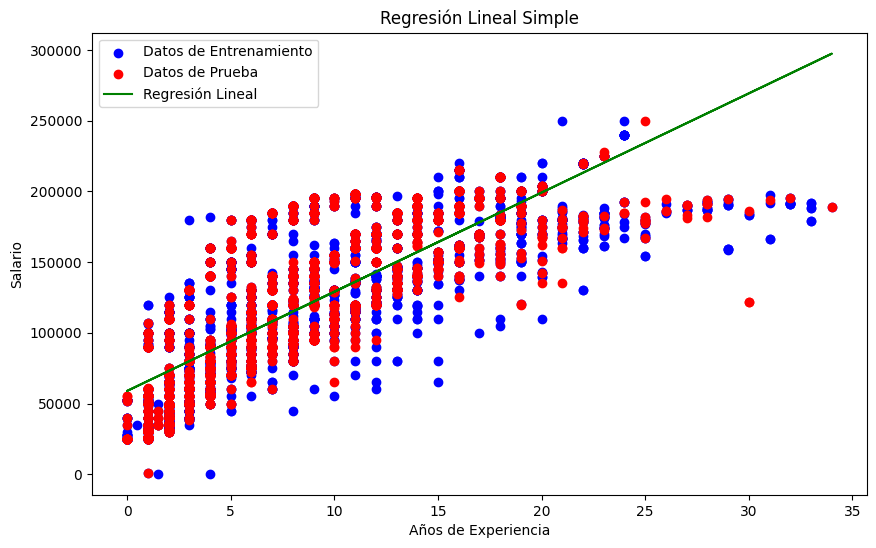

In [8]:
# Gráfica
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', label='Datos de Entrenamiento')
plt.scatter(X_test, y_test, color='red', label='Datos de Prueba')
plt.plot(X_test, predictions, color = 'green', label='Regresión Lineal')
plt.xlabel('Años de Experiencia')
plt.ylabel('Salario')
plt.title('Regresión Lineal Simple')
plt.legend()

## Regresión Lineal Múltiple

$$
Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_p X_p + \varepsilon
$$

**Donde:**
- $Y$: variable dependiente (objetivo)
- $\beta_0$: intercepto (valor de $Y$ cuando todas las $X$ son 0)
- $\beta_1, \dots, \beta_p$: coeficientes (pendientes) de cada variable independiente
- $X_1, \dots, X_p$: variables independientes (predictores)
- $\varepsilon$: término de error (residuo)

### Forma matricial

$$
\mathbf{Y} = \mathbf{X}\boldsymbol{\beta} + \boldsymbol{\varepsilon}
$$

### Estimación de coeficientes (Mínimos Cuadrados Ordinarios)

$$
\hat{\boldsymbol{\beta}} = (\mathbf{X}^\top \mathbf{X})^{-1} \mathbf{X}^\top \mathbf{Y}
$$

### Predicción

$$
\hat{Y} = \hat{\beta}_0 + \hat{\beta}_1 X_1 + \hat{\beta}_2 X_2 + \dots + \hat{\beta}_p X_p
$$


In [9]:
# Importar librerías
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [10]:
# Download latest version
import kagglehub
path = kagglehub.dataset_download("awaiskaggler/insurance-csv")

print("Path to dataset files:", path)

100%|██████████| 13.4k/13.4k [00:00<00:00, 10.5MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/awaiskaggler/insurance-csv/versions/1


In [11]:
df = pd.read_csv(path + "/insurance.csv")
df

,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86
...,...,...,...,...,...,...,...
1333,50,male,31.0,3,no,northwest,10600.55
1334,18,female,31.9,0,no,northeast,2205.98
1335,18,female,36.9,0,no,southeast,1629.83
1336,21,female,25.8,0,no,southwest,2007.95


In [12]:
# Codificación de variables categóricas
d1 = {'male': 1, 'female': 2}
d2 = {'yes': 1, 'no': 2}

df['sex'] = df['sex'].map(d1)
df['smoker'] = df['smoker'].map(d2)

# Aplicar One-Hot Encoding a la columna 'region'
df = pd.get_dummies(df, columns=['region'], drop_first=True)
df

,age,sex,bmi,children,smoker,expenses,region_northwest,region_southeast,region_southwest
0,19,2,27.9,0,1,16884.92,False,False,True
1,18,1,33.8,1,2,1725.55,False,True,False
2,28,1,33.0,3,2,4449.46,False,True,False
3,33,1,22.7,0,2,21984.47,True,False,False
4,32,1,28.9,0,2,3866.86,True,False,False
...,...,...,...,...,...,...,...,...,...
1333,50,1,31.0,3,2,10600.55,True,False,False
1334,18,2,31.9,0,2,2205.98,False,False,False
1335,18,2,36.9,0,2,1629.83,False,True,False
1336,21,2,25.8,0,2,2007.95,False,False,True


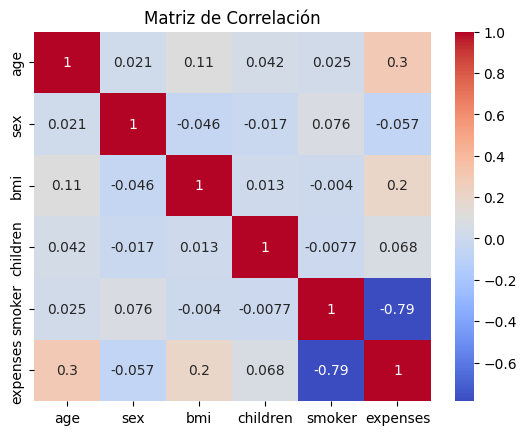

In [13]:
# Matriz de correlación
import seaborn as sns
import matplotlib.pyplot as plt

# Seleccionamos las columnas deseadas y calculamos la correlación
columnas_interes = ['age', 'sex', 'bmi', 'children', 'smoker', 'expenses']
corr_matrix = df[columnas_interes].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show()

In [14]:
# Selección de variables importantes
X = df.loc[:,['age','bmi','smoker']]
y = df.iloc[:,5]

In [15]:
# Separación del conjunto de datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [16]:
# Crear la regresión lineal
reg = LinearRegression()
reg.fit(X_train, y_train)

LinearRegression()

In [17]:
# Predicciones y exactitud
y_pred = reg.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(f"R^2: {r2}")

R^2: 0.7567996129313421


In [18]:
# Prueba
prueba = pd.DataFrame({'age':[36],'bmi':[27],'smoker':[0]})
print('El cobro del seguro es: ', round(reg.predict(prueba)[0],2))

El cobro del seguro es:  53905.7


In [19]:
# Coeficientes
print('w1, w2, w3: ', reg.coef_)
print('w0: ', reg.intercept_)

w1, w2, w3:  [   258.94072065    303.47111341 -23722.84761499]
w0:  36390.1107884968


## Regresión Polinómica

### 1. Forma general (una sola variable $x$)

$$
\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^3 + \dots + \beta_d x^d + \varepsilon
$$

Donde:
* $\hat{y}$ es el valor predicho.
* $\beta_i$ son los coeficientes estimados.
* $d$ es el grado del polinomio.
* $\varepsilon$ es el término de error.

### 2. Forma general (múltiples variables $X$)

Si tienes múltiples variables independientes $x_1, x_2, \dots, x_p$, la ecuación general incluye todas las combinaciones de potencias hasta el grado $d$:

$$
\hat{y} = \beta_0 + \sum_{j=1}^{p} \sum_{i=1}^{d} \beta_{ji} x_j^i + \varepsilon
$$

### 3. Forma matricial

Si definimos un vector de características transformadas $\phi(x)$, el modelo se escribe como:

$$
\hat{y} = \phi(x)^T \beta
$$

Donde $\phi(x) = [1, x, x^2, \dots, x^d]^T$.


In [20]:
# Download latest version
path = kagglehub.dataset_download("uciml/autompg-dataset")

print("Path to dataset files:", path)

# List all files in the downloaded directory to check the exact file name
print("Files in directory:", os.listdir(path))

# Assuming the CSV is directly inside 'path' or finding it dynamically:
# (If there's only one CSV file, you can find it like this:)
csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
csv_path = os.path.join(path, csv_file)

df = pd.read_csv(csv_path)
df.head()

100%|██████████| 6.31k/6.31k [00:00<00:00, 11.1MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/uciml/autompg-dataset/versions/3
Files in directory: ['auto-mpg.csv']


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


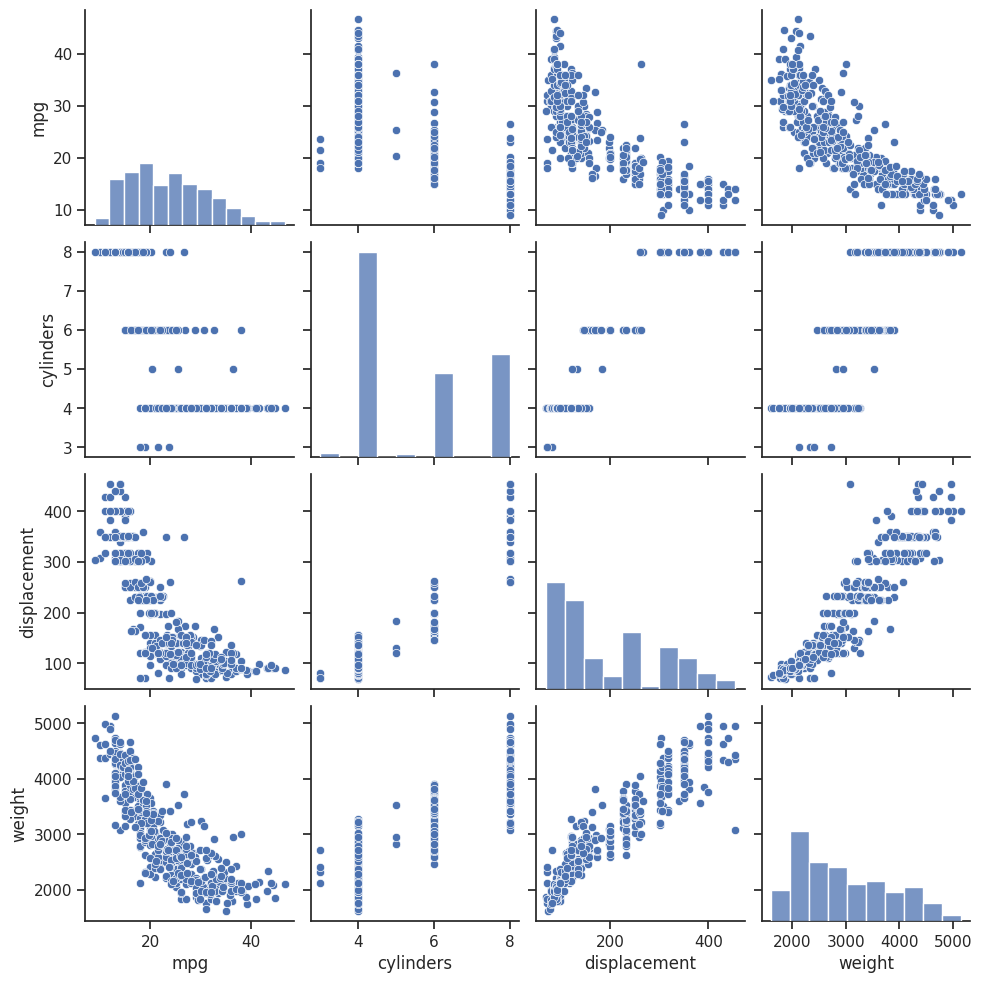

In [21]:
# Matriz de dispersión
sns.set(style="ticks")
sns.pairplot(data=df, vars=['mpg', 'cylinders', 'displacement', 'weight'])

In [22]:
# Variable predictora
X = df[['displacement']].values
# Variable objetivo
y = df['mpg'].values

# Division de los datos en conjunto de entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=20)

In [23]:
# Modelo Polinomial (cuadrático)

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

## Transformador
polinomio = PolynomialFeatures(degree=2)
polinomio_transformado = polinomio.fit_transform(X_train)
print(polinomio_transformado)
print('-----------------------------------------------------------------------')

## Calculo de coeficientes
reg_pol = LinearRegression()
reg_pol.fit(polinomio_transformado, y_train)
print('Coeficientes:', reg_pol.coef_)
print('Intersección:', reg_pol.intercept_)

[[1.00000e+00 4.29000e+02 1.84041e+05]
 [1.00000e+00 9.10000e+01 8.28100e+03]
 [1.00000e+00 4.00000e+02 1.60000e+05]
 [1.00000e+00 1.45000e+02 2.10250e+04]
 [1.00000e+00 6.80000e+01 4.62400e+03]
 [1.00000e+00 1.46000e+02 2.13160e+04]
 [1.00000e+00 4.00000e+02 1.60000e+05]
 [1.00000e+00 3.18000e+02 1.01124e+05]
 [1.00000e+00 3.07000e+02 9.42490e+04]
 [1.00000e+00 3.18000e+02 1.01124e+05]
 [1.00000e+00 2.62000e+02 6.86440e+04]
 [1.00000e+00 2.50000e+02 6.25000e+04]
 [1.00000e+00 9.80000e+01 9.60400e+03]
 [1.00000e+00 1.20000e+02 1.44000e+04]
 [1.00000e+00 8.50000e+01 7.22500e+03]
 [1.00000e+00 9.10000e+01 8.28100e+03]
 [1.00000e+00 9.70000e+01 9.40900e+03]
 [1.00000e+00 1.40000e+02 1.96000e+04]
 [1.00000e+00 1.08000e+02 1.16640e+04]
 [1.00000e+00 1.21000e+02 1.46410e+04]
 [1.00000e+00 2.50000e+02 6.25000e+04]
 [1.00000e+00 7.10000e+01 5.04100e+03]
 [1.00000e+00 9.00000e+01 8.10000e+03]
 [1.00000e+00 1.99000e+02 3.96010e+04]
 [1.00000e+00 9.80000e+01 9.60400e+03]
 [1.00000e+00 2.50000e+02

Text(0, 0.5, 'MPG')

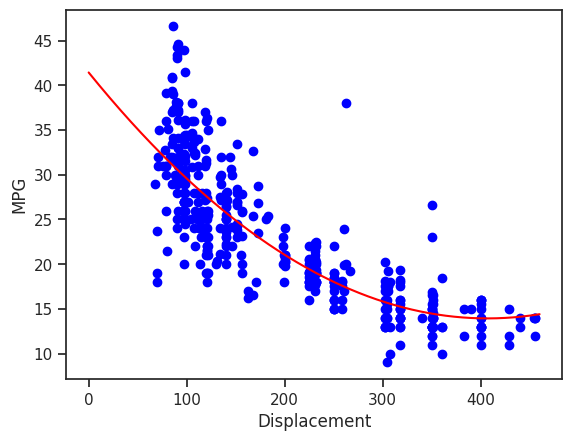

In [24]:
# Gráfica
plt.scatter(X, y, color='blue')
XX = np.arange(0.0, 460, 0.1)
yy = reg_pol.intercept_ + reg_pol.coef_[1] * XX + reg_pol.coef_[2] * XX**2
plt.plot(XX, yy, color='red')
plt.xlabel('Displacement')
plt.ylabel('MPG')

In [25]:
# Comparación modelo de regresión lineal vs polinomica
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Modelo de regresion lineal
reg_lineal = LinearRegression()
reg_lineal.fit(X_train, y_train)
y_pred_lineal = reg_lineal.predict(X_test)
print('Modelo de regresión lineal')
print('MAE: %.3f'% mean_absolute_error(y_test, y_pred_lineal))
print('MSE: %.3f'% mean_squared_error(y_test, y_pred_lineal))
print('R2: %.3f'% r2_score(y_test, y_pred_lineal))

## Modelo de regresion polinómica
y_pred_pol = reg_pol.predict(polinomio.fit_transform(X_test))
print('Modelo de regresión polinómica')
print('MAE: %.3f'% mean_absolute_error(y_test, y_pred_pol))
print('MSE: %.3f'% mean_squared_error(y_test, y_pred_pol))
print('R2: %.3f'% r2_score(y_test, y_pred_pol))

Modelo de regresión lineal
MAE: 4.036
MSE: 25.102
R2: 0.632
Modelo de regresión polinómica
MAE: 3.479
MSE: 20.945
R2: 0.693


## Evaluación de modelos de regresión

### 1. **Mean Absolute Error (MAE)**
El **Error Absoluto Medio (MAE)** mide el promedio de los errores absolutos entre los valores predichos y los valores reales. Es una métrica robusta que no penaliza los errores grandes de manera desproporcionada.

**Fórmula:**
$$
\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|
$$

- $n$: Número de observaciones.
- $y_i$: Valor real de la observación $i$.
- $\hat{y}_i$: Valor predicho para la observación $i$.

**Interpretación:**
- Valores más cercanos a **0** indican un mejor ajuste del modelo.
- Es fácil de interpretar porque está en las mismas unidades que la variable objetivo.

---

### 2. **Mean Squared Error (MSE)**
El **Error Cuadrático Medio (MSE)** mide el promedio de los errores al cuadrado entre los valores predichos y los valores reales. Penaliza los errores grandes más que los pequeños, lo que lo hace sensible a valores atípicos.

**Fórmula:**
$$
\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$

- $n$: Número de observaciones.
- $y_i$: Valor real de la observación $i$.
- $\hat{y}_i$: Valor predicho para la observación $i$.

**Interpretación:**
- Valores más cercanos a **0** indican un mejor ajuste del modelo.
- Al estar al cuadrado, las unidades son diferentes a las de la variable objetivo, lo que puede dificultar su interpretación directa.

---

### 3. **Root Mean Squared Error (RMSE)**
La **Raíz del Error Cuadrático Medio (RMSE)** es simplemente la raíz cuadrada del MSE. Mantiene la penalización fuerte a los errores grandes, pero devuelve la métrica a las unidades originales de la variable objetivo.

**Fórmula:**
$$
\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}
$$

- $n$: Número de observaciones.
- $y_i$: Valor real de la observación $i$.
- $\hat{y}_i$: Valor predicho para la observación $i$.

**Interpretación:**
- Valores más cercanos a **0** indican un mejor ajuste del modelo.
- Es muy utilizada porque penaliza los errores grandes y, al estar en la misma unidad que $y$, resulta más intuitiva que el MSE.

---

### 4. **Coeficiente de Determinación ($R^2$)**
El **coeficiente de determinación ($R^2$)** mide la proporción de la varianza en la variable dependiente que es explicada por el modelo. Es una métrica que va desde **0** hasta **1**, donde valores más cercanos a **1** indican un mejor ajuste.

**Fórmula:**
$$
R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}
$$

- $n$: Número de observaciones.
- $y_i$: Valor real de la observación $i$.
- $\hat{y}_i$: Valor predicho para la observación $i$.
- $\bar{y}$: Media de los valores reales.

**Interpretación:**
- **$R^2 = 1$**: El modelo explica el 100% de la variabilidad de los datos.
- **$R^2 = 0$**: El modelo no explica la variabilidad de los datos.
- **$R^2 < 0$**: El modelo es peor que una línea horizontal (peor que predecir siempre la media).

---

### 5. **R² Ajustado (Adjusted $R^2$)**
El **R² ajustado** modifica el $R^2$ clásico penalizando la inclusión de variables independientes (predictoras) que no aportan información real al modelo. A diferencia del $R^2$ normal (que siempre sube o se queda igual al agregar variables), este puede disminuir si una nueva variable no mejora el modelo lo suficiente.

**Fórmula:**
$$
R^2_{\text{adj}} = 1 - \frac{(1 - R^2)(n - 1)}{n - p - 1}
$$

- $n$: Número de observaciones.
- $p$: Número de variables predictoras (características) en el modelo.
- $R^2$: Coeficiente de determinación estándar.

**Interpretación:**
- Es fundamental para comparar modelos de regresión múltiple con diferente número de variables.
- Siempre será menor o igual que el $R^2$ estándar.

## Regularización

###  [Regresión Ridge (L2)](https://www.youtube.com/watch?v=Q81RR3yKn30)

**Objetivo:** Reducir la complejidad del modelo penalizando coeficientes grandes.

**Fórmula de la función de pérdida:**
$$
\text{Pérdida}_{\text{Ridge}} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \lambda \sum_{j=1}^{p} \beta_j^2
$$

- $\lambda$: Parámetro de regularización (controla la fuerza de la penalización).
- $\beta_j^2$: Cuadrado del coeficiente $j$-ésimo.

**Efecto:**
- Todos los coeficientes se reducen, pero **ninguno llega a cero**.
- Útil para **multicolinealidad**.

**Interpretación geométrica:**
- La penalización L2 restringe los coeficientes a una **esfera** en el espacio de parámetros.

---

### [Regresión Lasso (L1)](https://www.youtube.com/watch?v=NGf0voTMlcs)

**Objetivo:** Reducir la complejidad del modelo **y seleccionar variables** eliminando las menos relevantes.

**Fórmula de la función de pérdida:**
$$
\text{Pérdida}_{\text{Lasso}} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \lambda \sum_{j=1}^{p} |\beta_j|
$$

**Efecto:**
- Algunos coeficientes **llegan a cero**, lo que equivale a eliminar la variable correspondiente.
- Útil para **selección de características**.

**Interpretación geométrica:**
- La penalización L1 restringe los coeficientes a un **diamante (rombo)** en el espacio de parámetros.

---

### [Elastic Net (Combinación L1 + L2)](https://www.youtube.com/watch?v=1dKRdX9bfIo&t=157s)

**Objetivo:** Combinar las ventajas de Ridge y Lasso.

**Fórmula de la función de pérdida:**
$$
\text{Pérdida}_{\text{Elastic Net}} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \lambda_1 \sum_{j=1}^{p} |\beta_j| + \lambda_2 \sum_{j=1}^{p} \beta_j^2
$$

- $\lambda_1$: Parámetro para la penalización L1.
- $\lambda_2$: Parámetro para la penalización L2.

**Efecto:**
- **Selección de variables** (como Lasso) + **estabilidad** (como Ridge).
- Útil cuando hay **muchas variables correlacionadas**.

---

### [Comparación de Métodos](https://www.youtube.com/watch?v=Xm2C_gTAl8c)

| **Método** | **Penalización** | **Selección de Variables** | **Multicolinealidad** | **Interpretabilidad** |
| :--- | :--- | :--- | :--- | :--- |
| **Ridge (L2)** | Suma de cuadrados ($\beta_j^2$) | No | Sí | Media |
| **Lasso (L1)** | Suma de valores absolutos ($|\beta_j|$) | Sí | No (inestable) | Alta |
| **Elastic Net** | Combinación L1 + L2 | Sí | Sí | Alta |

In [26]:
df.drop(columns='car name', inplace = True)
df.replace('?', np.nan, inplace=True)
df.dropna(inplace=True)
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,18.0,8,307.0,130,3504,12.0,70,1
1,15.0,8,350.0,165,3693,11.5,70,1
2,18.0,8,318.0,150,3436,11.0,70,1
3,16.0,8,304.0,150,3433,12.0,70,1
4,17.0,8,302.0,140,3449,10.5,70,1
...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86,2790,15.6,82,1
394,44.0,4,97.0,52,2130,24.6,82,2
395,32.0,4,135.0,84,2295,11.6,82,1
396,28.0,4,120.0,79,2625,18.6,82,1


In [27]:
X = df.iloc[:,1:].values
y = df['mpg'].values

In [28]:
# Modelo de regresión polinomica

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=20)

polinomio2 = PolynomialFeatures(degree=2)
X_train_transformado = polinomio2.fit_transform(X_train)
X_test_transformado = polinomio2.fit_transform(X_test)

reg_pol = LinearRegression()
reg_pol.fit(X_train_transformado, y_train)

LinearRegression()

In [29]:
y_pred = reg_pol.predict(X_train_transformado)
print('R2 con datos de entrenamiento: %.3f'% r2_score(y_train, y_pred))
y_pred = reg_pol.predict(X_test_transformado)
print('R2 con datos de prueba: %.3f'% r2_score(y_test, y_pred))

R2 con datos de entrenamiento: 0.893
R2 con datos de prueba: 0.881


In [30]:
# Regresión Ridge

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_estand = scaler.fit_transform(X_train_transformado)
X_test_estand = scaler.transform(X_test_transformado)

reg_ridge = Ridge(alpha=1)
reg_ridge.fit(X_train_estand, y_train)

y_pred = reg_ridge.predict(X_train_estand)
print('R2 con datos de entrenamiento: %.3f'% r2_score(y_train, y_pred))

y_pred = reg_ridge.predict(X_test_estand)
print('R2 con datos de prueba: %.3f'% r2_score(y_test, y_pred))

R2 con datos de entrenamiento: 0.876
R2 con datos de prueba: 0.898


## Búsqueda de cuadrícula para encontrar los hiperparámetros óptimos (Grid Search)

In [33]:
# Grud Search
from sklearn.model_selection import GridSearchCV

reg_ridge = Ridge()
grilla = GridSearchCV(reg_ridge, {'alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]}, cv = 5, scoring = 'r2', verbose = 1)
grilla.fit(X_train_estand, y_train)
print('El mejor valor de lambda es:', grilla.best_params_)
print('El mejor valor de R2 es:', grilla.best_score_)

Fitting 5 folds for each of 7 candidates, totalling 35 fits
El mejor valor de lambda es: {'alpha': 0.1}
El mejor valor de R2 es: 0.8543003491126131


In [34]:
reg_ridge2 = Ridge(alpha = 0.1)
reg_ridge2.fit(X_train_estand, y_train)
y_pred = reg_ridge2.predict(X_test_estand)
print('R2 con datos de prueba: %.3f'% r2_score(y_test, y_pred))

R2 con datos de prueba: 0.892
